# Anderson localization in one dimension

In a disordered medium, waves scattered back and forth by the random potential interfere. In one
dimension the interference is always destructive enough to stop transport completely: *every*
eigenstate is localized, decaying as $e^{-\gamma|x|}$, however weak the disorder (Anderson, Phys. Rev.
**109**, 1492 (1958); Mott and Twose, Adv. Phys. **10**, 107 (1961)). A wavepacket therefore stops
spreading, unlike a classical particle with energy far above the potential, which would just fly
through. The effect was observed with matter waves of a Bose–Einstein condensate in a laser speckle
potential (Billy et al., Nature **453**, 891 (2008)).

In [ ]:
# On Colab (or anywhere without the package), install it from GitHub first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72

## Disorder and a wavepacket

`RandomPotential1d` draws a Gaussian random field with correlation function
$C(\Delta x) = \delta V^2 \exp(-\Delta x^2/2\ell^2)$. A Gaussian wavepacket with mean momentum $k_0$ and a
small momentum spread starts at $x = 0$. Its energy $k_0^2/2 = 0.5$ is twice the standard deviation of
the potential, so classically it would move almost freely.

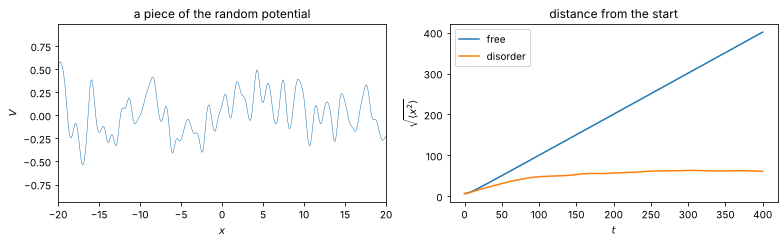

In [2]:
size, N = (-400.0, 400.0), 2**13
x = np.linspace(*size, N, endpoint=False)
ell, dV = 0.5, 0.25
corr = lambda d: np.exp(-(d**2) / (2 * ell**2))


sigma0 = 10.0  # packet width; momentum spread 1/sigma0


def run(k0, seed, dt=0.05, n_steps=8000):
    pot = so.RandomPotential1d(corr, x, dV, rng=seed, normalize="std")
    grid = so.Grid1d(size, N, pot, so.Gaussian1d(0.0, sigma0, k0))
    obs = so.analyzers.Observables()
    obs(grid)
    late = so.analyzers.IntegratedDensity()  # time-averaged density over the second half
    prop = so.SplitOperator()
    prop.propagate(grid, dt, n_steps // 2, callback=obs, every=50)
    prop.propagate(grid, dt, n_steps // 2, callback=[obs, late], every=50)
    return grid, obs, late.density / (late.density.sum() * grid.dx)


k0 = 1.0
grid, obs, _ = run(k0, seed=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(x, np.real(grid.V), lw=0.5)
ax1.set(xlim=(-20, 20), xlabel="$x$", ylabel="$V$", title="a piece of the random potential")
free = np.sqrt((k0 * obs.t) ** 2 + sigma0**2 / 2 * (1 + obs.t**2 / sigma0**4))
ax2.plot(obs.t, free, label="free")
ax2.plot(obs.t, np.hypot(obs.position, obs.width), label="disorder")
ax2.set(xlabel="$t$", ylabel=r"$\sqrt{\langle x^2\rangle}$", title="distance from the start")
ax2.legend()
plt.tight_layout()

Without the potential the packet would move away ballistically, $\sqrt{\langle x^2\rangle} \approx k_0 t$.
In the random potential its distance from the start grows at first, while the packet has not yet
"noticed" the interference, and then saturates.

## Exponential tails

On a logarithmic scale, the density averaged over the second half of the propagation and over a few
realizations of the disorder falls off exponentially on both sides.

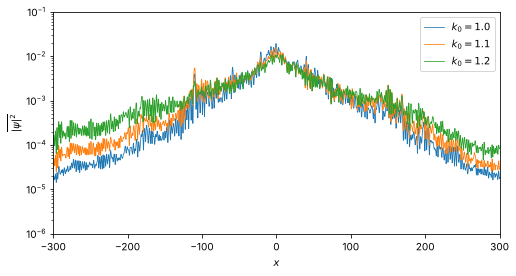

In [3]:
energies = (1.0, 1.1, 1.2)
seeds = range(4)
profiles = {k: np.mean([run(k, seed)[2] for seed in seeds], axis=0) for k in energies}

for k, rho in profiles.items():
    plt.semilogy(x, rho, lw=0.8, label=f"$k_0 = {k}$")
plt.xlim(-300, 300)
plt.ylim(1e-6, 1e-1)
plt.xlabel("$x$")
plt.ylabel(r"$\overline{|\psi|^2}$")
plt.legend();

## Localization length versus energy

For weak disorder, the Born approximation gives the inverse localization length from the power
spectrum $S(q) = \int C(\Delta x)\, e^{iq\Delta x}\, d\Delta x = \sqrt{2\pi}\,\ell\,\delta V^2 e^{-q^2\ell^2/2}$
of the potential at the backscattering momentum $q = 2k$:

$$\gamma(k) = \frac{S(2k)}{2k^2}.$$

Only Fourier components at $2k$ reflect a wave with momentum $k$, so for a smooth potential, $k\ell \gtrsim 1$,
$\xi = 1/\gamma$ grows very quickly with energy. Below, $\xi$ is fitted to the tails for
$30 < |x| < 150$. The fitted lengths follow the Born estimate within about 5%. The estimate needs weak
disorder, $\delta V \ll E$: for $k_0 \lesssim 0.8$, where $E$ approaches $\delta V$, fit and estimate no longer agree.

k0 = 1.0: xi_fit = 44.2, Born: 42.1
k0 = 1.1: xi_fit = 59.4, Born: 56.6
k0 = 1.2: xi_fit = 79.1, Born: 75.5


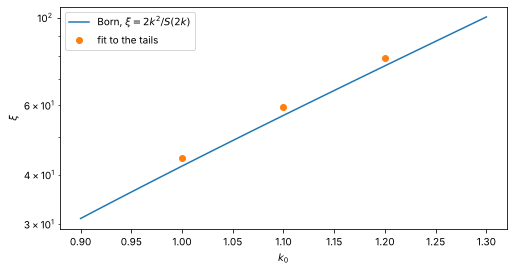

In [4]:
S = lambda q: np.sqrt(2 * np.pi) * ell * dV**2 * np.exp(-(q**2) * ell**2 / 2)
tail = (np.abs(x) > 30) & (np.abs(x) < 150)
xi_fit = [-1 / np.polyfit(np.abs(x[tail]), np.log(profiles[k][tail]), 1)[0] for k in energies]

k = np.linspace(0.9, 1.3, 100)
plt.semilogy(k, 2 * k**2 / S(2 * k), label=r"Born, $\xi = 2k^2/S(2k)$")
plt.semilogy(energies, xi_fit, "o", label="fit to the tails")
plt.xlabel("$k_0$")
plt.ylabel(r"$\xi$")
plt.legend()
for k0, xi in zip(energies, xi_fit):
    print(f"k0 = {k0}: xi_fit = {xi:.1f}, Born: {2 * k0**2 / S(2 * k0):.1f}")